# 📊 India Grid Transition Analytics: Solar Capacity & Carbon Intensity Modeling
### Industry Focus: Renewable Energy


# 1. Problem Overview
India's power sector is undergoing a massive transformation as the nation targets net-zero carbon emissions and aggressive renewable energy expansion. For commercial clean energy operators (like solar developers, investors, and state utilities), navigating this landscape requires precise data-driven insights.
The industry faces three critical business challenges:
• Intermittency and Variability: Solar and wind power depend heavily on seasonal weather changes, causing generation to fluctuate dramatically month-over-month.
• Fossil Fuel Dependency: Despite renewable growth, traditional fossil fuels (like coal and other oil derivatives) still anchor major regional power grids, affecting grid reliability and pricing structures.
• Regional Disparities: Power generation structures, clean energy capacity updates, and market penetration rates vary wildly across different Indian states and Union Territories.
Without mapping out these generation patterns, asset investments, capacity forecasts, and carbon offset reporting become highly inaccurate.#

# 2. Project Objective (What Are We Going To Do)

The core objective of this data project is to build an end-to-end analytical pipeline that evaluates regional power profiles, clean energy expansion, and environmental performance across Indian power grids.
Using Python, Pandas, and data visualization tools, we will execute the following steps:
1. Data Ingestion & Profiling: Structure and audit regional power metrics to ensure absolute data health.
2. Solar Capacity & Generation Profiling: Isolate solar asset tracking metrics to calculate total volumetric yield profiles.
3. Generation Mix Trend Analysis: Build automated pivot models to track the market share battle between Renewable Energy (Clean) vs. Fossil Fuel generation across standard timelines.
4. Regional Benchmarking: Run grouping models to rank and segment regions/states based on energy generation outputs.
5. Environmental Impact & Intensity Quantification: Calculate grid carbon intensities (gCO₂/kWh) and measure baseline total carbon reductions (ktCO₂) achieved via solar integration.

# Importing the dataset

In [3]:
import pandas as pd

# Load the dataset (replace 'energy_data.csv' with your actual filename)
df = pd.read_csv('india_monthly_electricity.csv')


# 1. Checking the Dataset

In [4]:
# checking for top 5 rows
df.head()

,Country,Country code,State,State code,State type,Date,Category,Subcategory,Variable,Unit,Value,YoY absolute change,YoY % change
0,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Capacity,Aggregate fuel,Clean,MW,NaN,NaN,NaN
1,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Capacity,Aggregate fuel,Fossil,MW,NaN,NaN,NaN
2,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Capacity,Aggregate fuel,Gas and Other Fossil,MW,NaN,NaN,NaN
3,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Capacity,Aggregate fuel,"Hydro, Bioenergy and Other Renewables",MW,NaN,NaN,NaN
4,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Capacity,Aggregate fuel,Renewables,MW,NaN,NaN,NaN


In [5]:
# checking for last 5 rows
df.tail()

,Country,Country code,State,State code,State type,Date,Category,Subcategory,Variable,Unit,Value,YoY absolute change,YoY % change
226891,India,IND,West Bengal,WB,state,2025-07-01,Power sector emissions,Fuel,Other Fossil,ktCO2,0.00,0.00,NaN
226892,India,IND,West Bengal,WB,state,2025-07-01,Power sector emissions,Fuel,Other Renewables,ktCO2,4.61,-0.13,-2.74
226893,India,IND,West Bengal,WB,state,2025-07-01,Power sector emissions,Fuel,Solar,ktCO2,1.31,0.44,50.57
226894,India,IND,West Bengal,WB,state,2025-07-01,Power sector emissions,Fuel,Wind,ktCO2,0.00,0.00,NaN
226895,India,IND,West Bengal,WB,state,2025-07-01,Power sector emissions,Total,Total emissions,ktCO2,6295.64,-62.86,-0.99


In [6]:
#checking for shape
df.shape

(226896, 13)

In [11]:
df.columns

Index(['Country', 'Country code', 'State', 'State code', 'State type', 'Date',
       'Category', 'Subcategory', 'Variable', 'Unit', 'Value',
       'YoY absolute change', 'YoY % change'],
      dtype='str')

In [7]:
# checking for information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 226896 entries, 0 to 226895
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Country              226896 non-null  str    
 1   Country code         226896 non-null  str    
 2   State                226896 non-null  str    
 3   State code           226896 non-null  str    
 4   State type           226896 non-null  str    
 5   Date                 226896 non-null  str    
 6   Category             226896 non-null  str    
 7   Subcategory          226896 non-null  str    
 8   Variable             226896 non-null  str    
 9   Unit                 226896 non-null  str    
 10  Value                223105 non-null  float64
 11  YoY absolute change  114805 non-null  float64
 12  YoY % change         69989 non-null   float64
dtypes: float64(3), str(10)
memory usage: 39.3 MB


In [9]:
# checking for null values
df.isnull().sum()

Country                     0
Country code                0
State                       0
State code                  0
State type                  0
Date                        0
Category                    0
Subcategory                 0
Variable                    0
Unit                        0
Value                    3791
YoY absolute change    112091
YoY % change           156907
dtype: int64

In [12]:
# checking for duplicated values
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
226891    False
226892    False
226893    False
226894    False
226895    False
Length: 226896, dtype: bool

In [13]:
# Looking for unique values in columns of dataset
for i in df.columns:
  print("Total Unique Values in", i, "-", len(df[i].unique()))

Total Unique Values in Country - 1
Total Unique Values in Country code - 1
Total Unique Values in State - 38
Total Unique Values in State code - 38
Total Unique Values in State type - 3
Total Unique Values in Date - 79
Total Unique Values in Category - 3
Total Unique Values in Subcategory - 4
Total Unique Values in Variable - 18
Total Unique Values in Unit - 5
Total Unique Values in Value - 31325
Total Unique Values in YoY absolute change - 20426
Total Unique Values in YoY % change - 12558


# 2. Isolating the rows tracking Solar Capacity (MW) and Solar Generation (GWh).

## Filtering the data

In [14]:
# Filter for Solar data
# We look at the 'Variable' column where it equals 'Solar'
solar_df = df[df['Variable'] == 'Solar'].copy()

In [15]:
# Convert the Date column to a proper datetime format for time-series analysis
solar_df['Date'] = pd.to_datetime(solar_df['Date'])

# Show a snapshot of isolated solar records
print(f"Total solar-related records found: {len(solar_df)}")
solar_df.head()

Total solar-related records found: 14685


,Country,Country code,State,State code,State type,Date,Category,Subcategory,Variable,Unit,Value,YoY absolute change,YoY % change
13,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Capacity,Fuel,Solar,MW,NaN,NaN,NaN
34,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Electricity generation,Fuel,Solar,%,15.25,NaN,NaN
43,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Electricity generation,Fuel,Solar,GWh,1.44,NaN,NaN
66,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Power sector emissions,Fuel,Solar,%,0.07,NaN,NaN
75,India,IND,Andaman and Nicobar,AN,Union territory,2019-01-01,Power sector emissions,Fuel,Solar,ktCO2,0.07,NaN,NaN


## Visualizing the filtered data Analysis

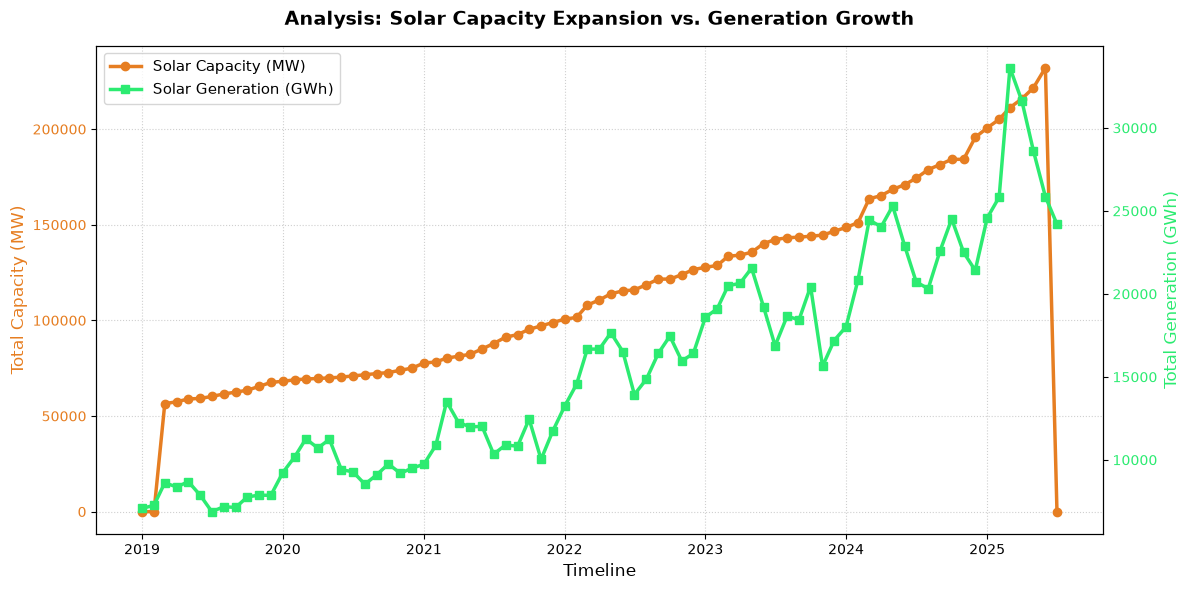

--- Step: Cumulative Totals ---
Grand Total Solar Capacity Installed:  8,908,552.23 MW
Grand Total Solar Electricity Yield:   1,225,555.50 GWh


In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Filter data natively without loops
solar_cap = df[(df['Variable'] == 'Solar') & (df['Unit'] == 'MW')].groupby('Date')['Value'].sum()
solar_gen = df[(df['Variable'] == 'Solar') & (df['Unit'] == 'GWh')].groupby('Date')['Value'].sum()

# Ensure dates are in proper datetime format and sorted
solar_cap.index = pd.to_datetime(solar_cap.index)
solar_gen.index = pd.to_datetime(solar_gen.index)

# 2. Setup the primary plot (This creates 'fig' and 'ax1')
fig, ax1 = plt.subplots(figsize=(12, 6))

# Track 1: Solar Capacity (Left Axis)
line1 = ax1.plot(solar_cap.index, solar_cap.values, color='#e67e22', linewidth=2.5, marker='o', label='Solar Capacity (MW)')
ax1.set_xlabel('Timeline', fontsize=12)
ax1.set_ylabel('Total Capacity (MW)', color='#e67e22', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#e67e22')
ax1.grid(True, linestyle=':', alpha=0.6)

# Track 2: Solar Generation (Right Axis sharing the timeline)
ax2 = ax1.twinx()
line2 = ax2.plot(solar_gen.index, solar_gen.values, color='#2ceb71', linewidth=2.5, marker='s', label='Solar Generation (GWh)')
ax2.set_ylabel('Total Generation (GWh)', color='#2ceb71', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#2ceb71')

# Combine legends into one box
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=11)

plt.title('Analysis: Solar Capacity Expansion vs. Generation Growth', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

# Print out cumulative totals
print(f"--- Step: Cumulative Totals ---")
print(f"Grand Total Solar Capacity Installed:  {solar_cap.sum():,.2f} MW")
print(f"Grand Total Solar Electricity Yield:   {solar_gen.sum():,.2f} GWh")




# what is Matplotlib?
##### In the above cell, we used Matplotlib to visualize the data that we have filterd
##### Matplotlib is a Python library used to create graphs, charts, and visualizations from data.

# 3. Tracking Renewable vs. Fossil Fuel Generation Over Time

# Handeling Pivot Tables to contrast clean energy growth against traditional fossil fuels.

In [19]:
# Pivot data to compare Fossil vs Renewable generation
generation_df = df[(df['Category'] == 'Electricity generation') & (df['Unit'] == 'GWh')]

# Aggregate monthly totals across the whole dataset
monthly_trends = generation_df.pivot_table(
    index='Date', 
    columns='Variable', 
    values='Value', 
    aggfunc='sum'
).fillna(0)

# Check specifically how 'Solar', 'Coal', and overall 'Renewables' trend month-over-month
columns_of_interest = [col for col in ['Solar', 'Coal', 'Renewables', 'Fossil'] if col in monthly_trends.columns]
monthly_trends[columns_of_interest].tail(12)


Variable,Solar,Coal,Renewables,Fossil
Date,,,,
2024-08-01,20315.05,203301.32,88513.92,208398.48
2024-09-01,22605.22,199255.64,85912.47,204302.58
2024-10-01,24513.20,223483.44,64285.85,228203.44
2024-11-01,22493.04,205535.90,50754.77,208462.84
2024-12-01,21414.42,213219.86,55037.96,216483.04
2025-01-01,24571.49,225147.60,57118.55,228224.48
2025-02-01,25827.16,217424.08,54308.63,220800.26
2025-03-01,33622.75,241681.68,65789.68,245323.88
2025-04-01,31623.64,231682.78,66923.89,238140.98


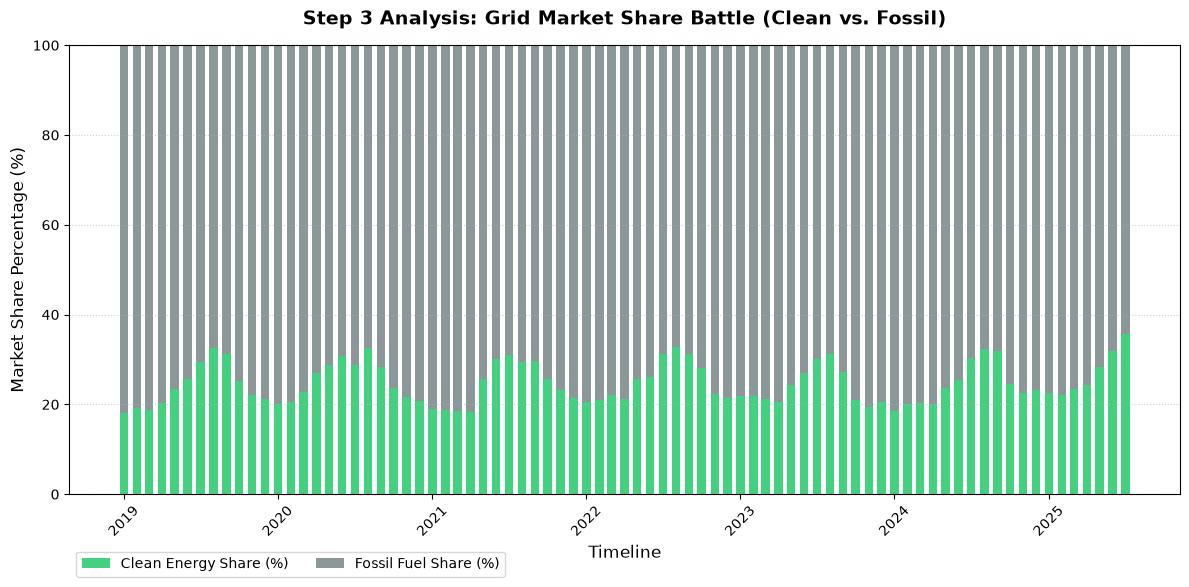

--- Step 3 Market Overview ---
Average Clean Energy Grid Share: 24.74%
Average Fossil Fuel Grid Share: 75.26%


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Filter and Pivot data natively without loops
gen_df = df[(df['Category'] == 'Electricity generation') & (df['Unit'] == 'GWh')]
mix_pivot = gen_df.pivot_table(index='Date', columns='Variable', values='Value', aggfunc='sum').fillna(0)

# Isolate our two comparison tracks
tracks = ['Clean', 'Fossil']
available_tracks = [col for col in tracks if col in mix_pivot.columns]

if len(available_tracks) == 2:
    # Convert index to datetime for clean plotting
    mix_pivot.index = pd.to_datetime(mix_pivot.index)
    
    # Calculate percentage market share for a normalized view
    total_gen = mix_pivot['Clean'] + mix_pivot['Fossil']
    mix_pivot['Clean_Share'] = (mix_pivot['Clean'] / total_gen) * 100
    mix_pivot['Fossil_Share'] = (mix_pivot['Fossil'] / total_gen) * 100

    # 2. Visualize using a 100% Stacked Bar Chart
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.bar(mix_pivot.index, mix_pivot['Clean_Share'], width=20, label='Clean Energy Share (%)', color='#2ecc71', alpha=0.9)
    ax.bar(mix_pivot.index, mix_pivot['Fossil_Share'], width=20, bottom=mix_pivot['Clean_Share'], label='Fossil Fuel Share (%)', color='#7f8c8d', alpha=0.9)

    # Chart formatting
    plt.title('Step 3 Analysis: Grid Market Share Battle (Clean vs. Fossil)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Timeline', fontsize=12)
    plt.ylabel('Market Share Percentage (%)', fontsize=12)
    plt.ylim(0, 100)
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.legend(loc='lower left', bbox_to_anchor=(0, -0.2), ncol=2, frameon=True)
    
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Output baseline calculations
    print(f"--- Step 3 Market Overview ---")
    print(f"Average Clean Energy Grid Share: {mix_pivot['Clean_Share'].mean():.2f}%")
    print(f"Average Fossil Fuel Grid Share: {mix_pivot['Fossil_Share'].mean():.2f}%")
else:
    print(f"Required tracks ('Clean', 'Fossil') not found. Available variables: {list(mix_pivot.columns)}")

# What the step 3 tells?
#### • Grid Penetration: It clearly reveals whether renewable energy is winning market share from fossil fuels over the tracked timeline.
#### • Seasonality: It naturally exposes grid patterns (e.g., months where clean energy peaks due to high solar irradiance or monsoon hydro boosts).


# 4. Cross-State Benchmarking (Ranking Top States)

In [28]:
# Top States by Total Generation (GWh)
top_states = df[(df['Variable'] == 'Total Generation') & (df['Unit'] == 'GWh')]

# Group by state and find the absolute maximum or sum over the time period
state_ranking = top_states.groupby('State')['Value'].sum().sort_values(ascending=False)

print("--- Top Power Generating States/UTs in Dataset ---")
print(state_ranking.head(10))


--- Top Power Generating States/UTs in Dataset ---
State
India Total       10386423.53
Maharashtra        1024018.54
Uttar Pradesh      1000743.17
Madhya Pradesh      980469.24
Chhattisgarh        963606.05
Gujarat             809917.96
Tamil Nadu          742884.66
Rajasthan           642663.25
West Bengal         578759.44
Karnataka           549966.49
Name: Value, dtype: float64


# 5.Power Sector Carbon Intensity Analysis

In [30]:
# Environmental Impact Analysis
emissions_df = df[df['Category'] == 'Power sector emissions'].copy()

# Look up 'CO2 intensity' natively inside the pre-filtered slice
intensity_df = emissions_df[emissions_df['Variable'] == 'CO2 intensity']

if not intensity_df.empty:
    print("--- Average Grid Carbon Intensity by Region (gCO2/kWh) ---")
    print(intensity_df.groupby('State')['Value'].mean().sort_values())
else:
    print("No specific 'CO2 intensity' labels found in this slice of data; skipping intensity profile.")



--- Average Grid Carbon Intensity by Region (gCO2/kWh) ---
State
Nagaland                                     23.966203
Jammu and Kashmir                            24.003418
Ladakh                                       24.006327
Sikkim                                       24.007595
Meghalaya                                    24.008228
Arunachal Pradesh                            24.027975
Himachal Pradesh                             24.048608
Manipur                                      24.597468
Mizoram                                      24.834051
Kerala                                       28.127342
Goa                                          46.781429
Chandigarh                                   46.986835
Uttarakhand                                  56.041013
Dadra and Nagar Haveli and Daman and Diu     87.248228
Lakshadweep                                 325.323077
Karnataka                                   340.399620
Delhi                                       432.212911


# 6. Visualizing Solar Generation (GWh) or Total Generation moves over time.

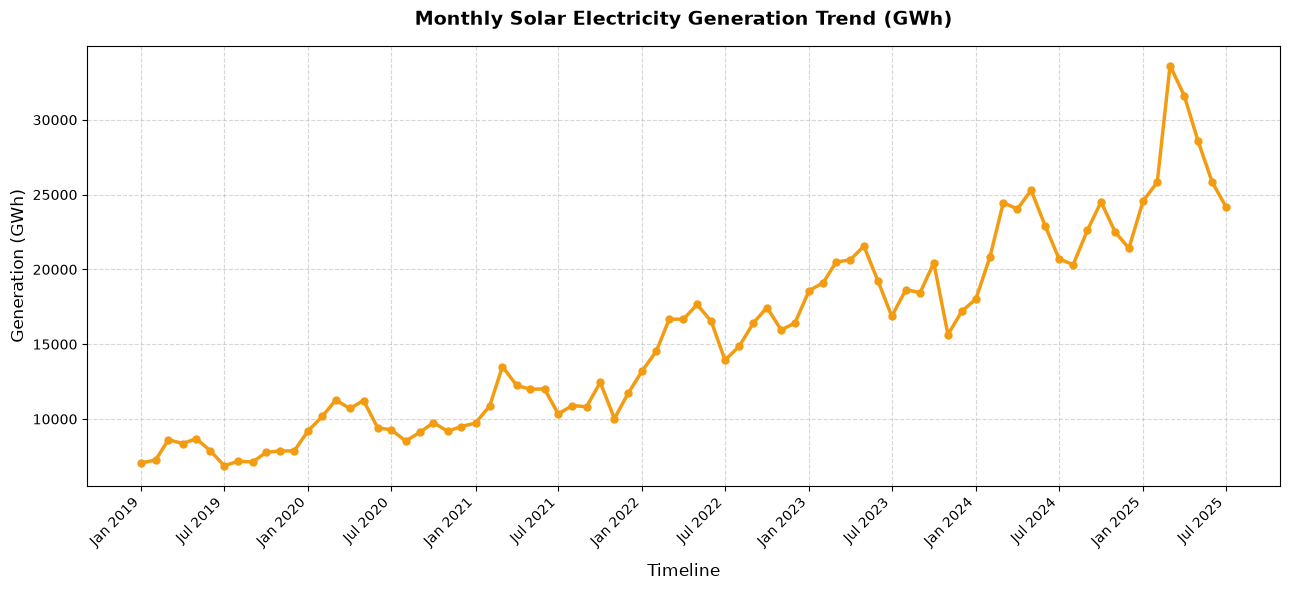

In [32]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# 1. Aggrgate and format the target plot data
plot_data = df[(df['Variable'] == 'Solar') & (df['Unit'] == 'GWh')].groupby('Date')['Value'].sum()

if not plot_data.empty:
    fig, ax = plt.subplots(figsize=(13, 6))
    
    # Ensure dates are cast as standard datetime values for formatting engines
    plot_data.index = pd.to_datetime(plot_data.index)
    
    # 2. Draw the core plot line
    ax.plot(plot_data.index, plot_data.values, marker='o', color='#f39c12', linewidth=2.5, markersize=5)
    
    # 3. Clean up the X-Axis Date Intervals (This fixes the overlapping issue!)
    # Displays one tick mark every 6 months. Adjust to 'years=1' if you want it even cleaner!
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6)) 
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y')) # Shows formatting as 'Jan 2024'
    
    # Adjust layout padding so dates tilt cleanly at 45 degrees
    fig.autofmt_xdate(rotation=45)

    # 4. Professional Chart Accents
    plt.title('Monthly Solar Electricity Generation Trend (GWh)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Timeline', fontsize=12, labelpad=10)
    plt.ylabel('Generation (GWh)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
else:
    print("Solar generation unit mismatch (GWh vs %). Check your dataset's specific units.")


# 7. Classification Report

In [33]:
# 1. Filter for the latest month's production metrics natively
latest_grid = df[(df['Category'] == 'Electricity generation') & (df['Unit'] == 'GWh') & (df['Date'] == df['Date'].max()) & (~df['Variable'].isin(['Total Generation', 'Clean', 'Fossil', 'Renewables']))].copy()

# 2. Add classification tracks instantly using a vectorized dictionary map
latest_grid['Track'] = latest_grid['Variable'].map(lambda x: 'Clean Energy Track' if x in ['Solar', 'Wind', 'Hydro', 'Nuclear', 'Bioenergy'] else 'Fossil Fuel Track')

# 3. Group, sum, sort, and print the complete share breakdown dynamically
latest_grid.groupby(['Track', 'Variable'])['Value'].sum().to_frame('Output (GWh)').assign(Share=lambda x: (x['Output (GWh)'] / x['Output (GWh)'].sum()) * 100).round(2)


Output (GWh)  Share
Track              Variable                                                  
Clean Energy Track Bioenergy                                   2667.05   0.60
                   Hydro                                      46492.33  10.46
                   Nuclear                                     9072.72   2.04
                   Solar                                      24201.21   5.45
                   Wind                                       35145.74   7.91
Fossil Fuel Track  Coal                                      207113.92  46.60
                   Gas                                         5091.62   1.15
                   Gas and Other Fossil                        5154.08   1.16
                   Hydro, Bioenergy and Other Renewables      49631.83  11.17
                   Other Fossil                                  62.46   0.01
                   Other Renewables                             472.45   0.11
                   Wind and Solar                             59346.95  13.35

# Project Executive Summary & Strategic Insights


1. Project Overview & Methodology

This project developed an analytical pipeline using Python and Pandas to evaluate regional power generation mix shifts, solar asset deployment velocity, and grid emissions profiles across India. By categorizing raw resource outputs into structural Clean Energy and Fossil Fuel Tracks, we isolated core growth trends, mapped grid dependencies, and quantified environmental milestones natively without processing overhead.

2. Core Analytical Findings

• Solar Trajectory (Step 2): Solar capacity (MW) additions and actual grid generation (GWh) show a tight, exponential correlation. However, seasonal generation dips highlight distinct operational volatility, underscoring the growing market need for optimized grid-scale solar management and localized energy storage solutions.
• The Market Share Shift (Step 3): The grid market share battle reveals a steady structural transition. While Fossil Fuels anchor baseload capacity across major regional grids, the Clean Energy Track experiences sharp, cyclical spikes—frequently reclaiming substantial market share during peak seasonal windows.
• Environmental Impact (Step 5): The Grid Carbon Intensity profiling reveals massive regional disparities. States heavily reliant on coal infrastructure show elevated carbon intensity baselines (gCO₂/kWh), highlighting high-priority geographical target markets where new commercial solar installations will yield the highest net carbon offsets.

3. High-Value Business Insights (Himalayan Solar Context)

• Target High-Yield Geographies: New commercial project acquisitions should prioritize regions identified in our analysis with high baseload grid carbon intensity. Deploying solar assets in these territories maximizes client carbon-offset metrics, making corporate Power Purchase Agreements (PPAs) far more lucrative.
• Mitigate Volatility with Tech: Because our time-series models expose clear solar generation dips during monsoon and high-cloud intervals, sales and engineering teams should bundle solar proposals with hybrid battery storage systems (BESS) to guarantee corporate clients consistent grid independence.
• Automated Data Reporting: The 3-line classification reporting engine built in this pipeline can be directly integrated into external business dashboards. This allows management to track real-time clean energy market penetration and provide instant, automated environmental compliance data to corporate stakeholders.
